In [1]:
import sys
import pandas as pd
import torch
import transformers

print("Python:", sys.version)
print("Interpreter:", sys.executable)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Setup successful!")

Python: 3.12.14 (main, Sep  1 2026, 14:09:38) [Clang 22.1.3 ]
Interpreter: /Users/saikiran/Desktop/amazon-reviews-sentiment-analysis/.venv/bin/python
Pandas: 3.1.0
PyTorch: 2.15.0
Setup successful!


In [2]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("data/Reviews.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)

print("Full dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

df.head()

Full dataset shape: (568454, 10)

Columns: ['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [3]:
# Reproducible initial sample
reviews = df.head(10_000).copy()

print("Reviews selected:", len(reviews))
print("\nMissing values:")
print(reviews[["Text", "Score"]].isnull().sum())

reviews[["Text", "Score"]].head()

Reviews selected: 10000

Missing values:
Text     0
Score    0
dtype: int64


,Text,Score
0,I have bought several of the Vitality canned d...,5
1,Product arrived labeled as Jumbo Salted Peanut...,1
2,This is a confection that has been around a fe...,4
3,If you are looking for the secret ingredient i...,2
4,Great taffy at a great price. There was a wid...,5


In [4]:
print("Dataset shape:", reviews.shape)
print("\nRating distribution:")
print(reviews["Score"].value_counts().sort_index())

print("\nDuplicate review texts:", reviews["Text"].duplicated().sum())
print("\nEmpty review texts:", reviews["Text"].isna().sum())

Dataset shape: (10000, 10)

Rating distribution:
Score
1     932
2     590
3     862
4    1433
5    6183
Name: count, dtype: int64

Duplicate review texts: 487

Empty review texts: 0


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

# Work on a copy so the original sample stays unchanged
reviews = reviews.copy()

# Convert ratings to integers
reviews["Score"] = reviews["Score"].astype(int)

print("Total reviews:", len(reviews))
print("Unique review texts:", reviews["Text"].nunique())
print("Duplicate review texts:", reviews["Text"].duplicated().sum())

Matplotlib is building the font cache; this may take a moment.


Total reviews: 10000
Unique review texts: 9513
Duplicate review texts: 487


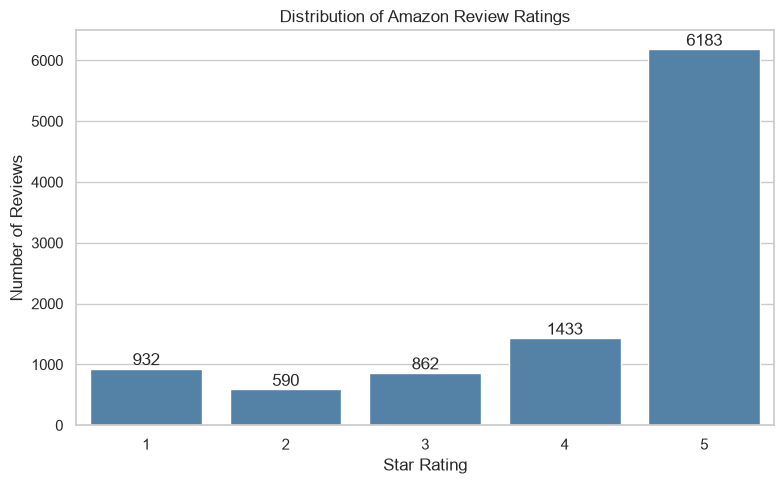

In [6]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=reviews,
    x="Score",
    color="steelblue",
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of Amazon Review Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

count    10000.000000
mean        76.230900
std         73.106483
min         10.000000
25%         33.000000
50%         54.000000
75%         94.000000
max       1513.000000
Name: review_word_count, dtype: float64


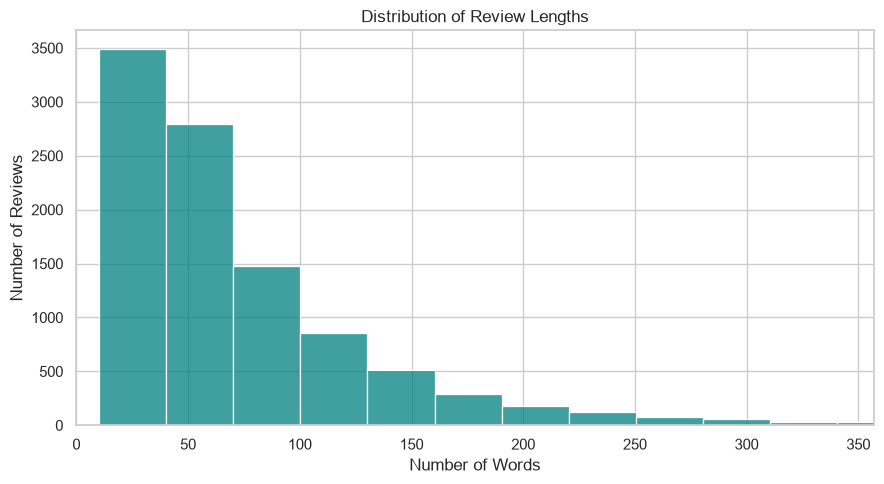

In [7]:
reviews["review_word_count"] = (
    reviews["Text"].astype(str).str.split().str.len()
)

print(reviews["review_word_count"].describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    data=reviews,
    x="review_word_count",
    bins=50,
    color="teal"
)

plt.xlim(0, reviews["review_word_count"].quantile(0.99))
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [8]:
for score in [1, 3, 5]:
    print(f"\n{'=' * 60}")
    print(f"STAR RATING: {score}")
    print("=" * 60)

    examples = reviews.loc[reviews["Score"] == score, "Text"].head(2)

    for i, text in enumerate(examples, start=1):
        print(f"\nExample {i}:\n{text[:500]}")


STAR RATING: 1

Example 1:
Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".

Example 2:
My cats have been happily eating Felidae Platinum for more than two years. I just got a new bag and the shape of the food is different. They tried the new food when I first put it in their bowls and now the bowls sit full and the kitties will not touch the food. I've noticed similar reviews related to formula changes in the past. Unfortunately, I now need to find a new food that my cats will eat.

STAR RATING: 3

Example 1:
This seems a little more wholesome than some of the supermarket brands, but it is somewhat mushy and doesn't have quite as much flavor either.  It didn't pass muster with my kids, so I probably won't buy it again.

Example 2:
The flavors are good.  However, I do not see any differce between this and Oaker Oats brand - they are both mushy.


In [9]:
import nltk

nltk.download("vader_lexicon", quiet=True)

from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

print("VADER is ready!")

VADER is ready!


In [10]:
from tqdm.auto import tqdm

tqdm.pandas()

reviews["vader_scores"] = reviews["Text"].progress_apply(
    sia.polarity_scores
)

reviews["vader_neg"] = reviews["vader_scores"].apply(lambda x: x["neg"])
reviews["vader_neu"] = reviews["vader_scores"].apply(lambda x: x["neu"])
reviews["vader_pos"] = reviews["vader_scores"].apply(lambda x: x["pos"])
reviews["vader_compound"] = reviews["vader_scores"].apply(
    lambda x: x["compound"]
)

reviews[["Text", "Score", "vader_neg", "vader_neu",
         "vader_pos", "vader_compound"]].head()


  0%|          | 0/10000 [00:00<?, ?it/s]

,Text,Score,vader_neg,vader_neu,vader_pos,vader_compound
0,I have bought several of the Vitality canned d...,5,0.000,0.695,0.305,0.9441
1,Product arrived labeled as Jumbo Salted Peanut...,1,0.138,0.862,0.000,-0.5664
2,This is a confection that has been around a fe...,4,0.091,0.754,0.155,0.8265
3,If you are looking for the secret ingredient i...,2,0.000,1.000,0.000,0.0000
4,Great taffy at a great price. There was a wid...,5,0.000,0.552,0.448,0.9468


In [11]:
def classify_vader(compound):
    if compound >= 0.05:
        return "Positive"
    elif compound <= -0.05:
        return "Negative"
    return "Neutral"

reviews["vader_sentiment"] = reviews["vader_compound"].apply(
    classify_vader
)

print("VADER sentiment distribution:")
print(reviews["vader_sentiment"].value_counts())

print("\nSample predictions:")
reviews[["Score", "Text", "vader_compound",
         "vader_sentiment"]].head(10)


VADER sentiment distribution:
vader_sentiment
Positive    8743
Negative    1049
Neutral      208
Name: count, dtype: int64

Sample predictions:


,Score,Text,vader_compound,vader_sentiment
0,5,I have bought several of the Vitality canned d...,0.9441,Positive
1,1,Product arrived labeled as Jumbo Salted Peanut...,-0.5664,Negative
2,4,This is a confection that has been around a fe...,0.8265,Positive
3,2,If you are looking for the secret ingredient i...,0.0000,Neutral
4,5,Great taffy at a great price. There was a wid...,0.9468,Positive
5,4,I got a wild hair for taffy and ordered this f...,0.8830,Positive
6,5,This saltwater taffy had great flavors and was...,0.9346,Positive
7,5,This taffy is so good. It is very soft and ch...,0.9487,Positive
8,5,Right now I'm mostly just sprouting this so my...,0.6369,Positive
9,5,This is a very healthy dog food. Good for thei...,0.8313,Positive


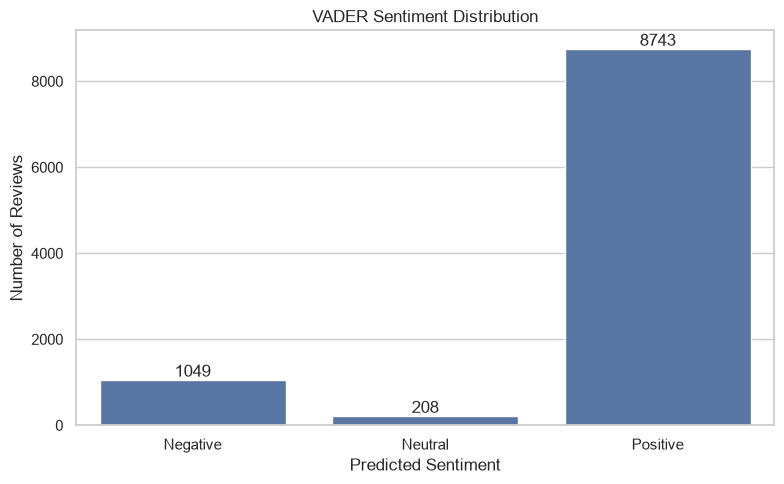

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

order = ["Negative", "Neutral", "Positive"]
ax = sns.countplot(
    data=reviews,
    x="vader_sentiment",
    order=order
)

plt.title("VADER Sentiment Distribution")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Reviews")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

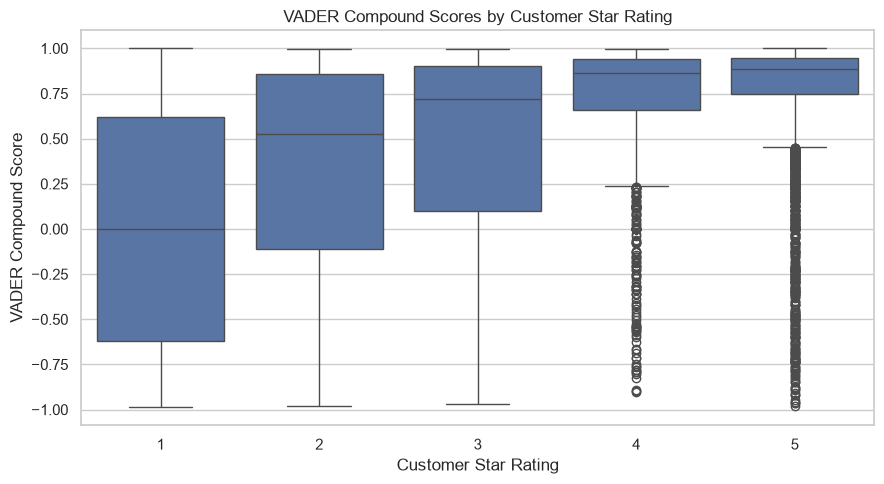

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=reviews,
    x="Score",
    y="vader_compound"
)

plt.title("VADER Compound Scores by Customer Star Rating")
plt.xlabel("Customer Star Rating")
plt.ylabel("VADER Compound Score")

plt.tight_layout()
plt.show()

In [15]:
import torch
import pandas as pd
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment"

device = torch.device("cpu")  # Works on your Mac without a GPU

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Labels:", model.config.id2label)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model loaded successfully!
Device: cpu
Labels: {0: 'LABEL_0', 1: 'LABEL_1', 2: 'LABEL_2'}


In [16]:
BATCH_SIZE = 16
MAX_LENGTH = 256

texts = reviews["Text"].fillna("").astype(str).tolist()

all_probabilities = []

for start in tqdm(range(0, len(texts), BATCH_SIZE), desc="RoBERTa"):
    batch_texts = texts[start:start + BATCH_SIZE]

    inputs = tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.inference_mode():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)

    all_probabilities.extend(probabilities.cpu().numpy())

probabilities = np.asarray(all_probabilities)

print("Prediction matrix shape:", probabilities.shape)

RoBERTa:   0%|          | 0/625 [00:00<?, ?it/s]

Prediction matrix shape: (10000, 3)


In [17]:
# CardiffNLP model label order: negative, neutral, positive
reviews["roberta_neg"] = probabilities[:, 0]
reviews["roberta_neu"] = probabilities[:, 1]
reviews["roberta_pos"] = probabilities[:, 2]

labels = np.array(["Negative", "Neutral", "Positive"])
reviews["roberta_sentiment"] = labels[probabilities.argmax(axis=1)]

reviews[
    ["Score", "Text", "vader_sentiment", "roberta_sentiment",
     "roberta_neg", "roberta_neu", "roberta_pos"]
].head(10)

,Score,Text,vader_sentiment,roberta_sentiment,roberta_neg,roberta_neu,roberta_pos
0,5,I have bought several of the Vitality canned d...,Positive,Positive,0.009624,0.049980,0.940395
1,1,Product arrived labeled as Jumbo Salted Peanut...,Negative,Negative,0.508986,0.452414,0.038600
2,4,This is a confection that has been around a fe...,Positive,Positive,0.003229,0.098068,0.898704
3,2,If you are looking for the secret ingredient i...,Neutral,Positive,0.002295,0.090219,0.907486
4,5,Great taffy at a great price. There was a wid...,Positive,Positive,0.001635,0.010302,0.988063
5,4,I got a wild hair for taffy and ordered this f...,Positive,Positive,0.006130,0.021796,0.972075
6,5,This saltwater taffy had great flavors and was...,Positive,Positive,0.001305,0.007774,0.990921
7,5,This taffy is so good. It is very soft and ch...,Positive,Positive,0.002029,0.005685,0.992285
8,5,Right now I'm mostly just sprouting this so my...,Positive,Positive,0.003874,0.094156,0.901970
9,5,This is a very healthy dog food. Good for thei...,Positive,Positive,0.003103,0.055912,0.940984


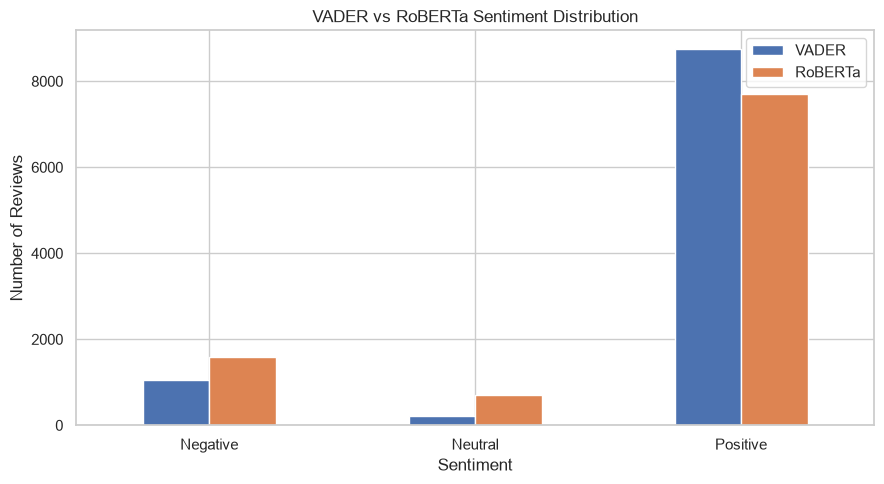

,VADER,RoBERTa
Negative,1049,1591
Neutral,208,706
Positive,8743,7703


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

comparison = pd.concat([
    reviews["vader_sentiment"].value_counts().rename("VADER"),
    reviews["roberta_sentiment"].value_counts().rename("RoBERTa")
], axis=1).fillna(0)

comparison = comparison.reindex(
    ["Negative", "Neutral", "Positive"]
)

comparison.plot(kind="bar", figsize=(9, 5))

plt.title("VADER vs RoBERTa Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(comparison)

In [19]:
agreement = (
    reviews["vader_sentiment"] == reviews["roberta_sentiment"]
).mean()

print(f"VADER-RoBERTa agreement: {agreement:.2%}")

display(pd.crosstab(
    reviews["vader_sentiment"],
    reviews["roberta_sentiment"],
    rownames=["VADER"],
    colnames=["RoBERTa"]
))

VADER-RoBERTa agreement: 82.24%


RoBERTa,Negative,Neutral,Positive
VADER,,,
Negative,736,116,197
Neutral,76,57,75
Positive,779,533,7431


In [20]:
disagreements = reviews[
    reviews["vader_sentiment"] != reviews["roberta_sentiment"]
].copy()

print("Disagreements:", len(disagreements))

display(
    disagreements[
        ["Score", "Text", "vader_compound",
         "vader_sentiment", "roberta_sentiment"]
    ].head(10)
)

Disagreements: 1776


,Score,Text,vader_compound,vader_sentiment,roberta_sentiment
3,2,If you are looking for the secret ingredient i...,0.0000,Neutral,Positive
11,5,One of my boys needed to lose some weight and ...,-0.7579,Negative,Neutral
12,1,My cats have been happily eating Felidae Plati...,0.2960,Positive,Negative
24,5,"I have lived out of the US for over 7 yrs now,...",0.3939,Positive,Negative
45,3,This seems a little more wholesome than some o...,0.0000,Neutral,Negative
49,3,This is the same stuff you can buy at the big ...,0.2363,Positive,Negative
53,3,we're used to spicy foods down here in south t...,-0.3612,Negative,Neutral
62,1,Arrived in 6 days and were so stale i could no...,0.0000,Neutral,Negative
73,1,Buyer Beware Please! This sweetener is not for...,0.9665,Positive,Negative
74,2,It is okay. I would not go out of my way to b...,0.2263,Positive,Neutral


In [21]:
def rating_to_sentiment(score):
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

reviews["rating_sentiment"] = reviews["Score"].apply(
    rating_to_sentiment
)

print("Rating-based sentiment distribution:")
print(reviews["rating_sentiment"].value_counts())

Rating-based sentiment distribution:
rating_sentiment
Positive    7616
Negative    1522
Neutral      862
Name: count, dtype: int64


In [23]:
uv pip install --python .venv/bin/python scikit-learn

/Users/saikiran/Desktop/amazon-reviews-sentiment-analysis/.venv/bin/python: No module named uv
Note: you may need to restart the kernel to use updated packages.


In [26]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support
)

y_true = reviews["rating_sentiment"]
class_order = ["Negative", "Neutral", "Positive"]

for model_name, column in [
    ("VADER", "vader_sentiment"),
    ("RoBERTa", "roberta_sentiment")
]:
    y_pred = reviews[column]

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=class_order,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(y_true, y_pred)

    print(f"\n{'=' * 45}")
    print(model_name)
    print(f"{'=' * 45}")
    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Macro precision:   {precision:.4f}")
    print(f"Macro recall:      {recall:.4f}")
    print(f"Macro F1-score:    {f1:.4f}")
    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=class_order,
        zero_division=0
    ))


VADER
Accuracy:          0.7884
Macro precision:   0.5392
Macro recall:      0.4665
Macro F1-score:    0.4796

Classification report:
              precision    recall  f1-score   support

    Negative       0.58      0.40      0.47      1522
     Neutral       0.21      0.05      0.08       862
    Positive       0.83      0.95      0.88      7616

    accuracy                           0.79     10000
   macro avg       0.54      0.47      0.48     10000
weighted avg       0.74      0.79      0.75     10000


RoBERTa
Accuracy:          0.8396
Macro precision:   0.6239
Macro recall:      0.6236
Macro F1-score:    0.6229

Classification report:
              precision    recall  f1-score   support

    Negative       0.71      0.74      0.73      1522
     Neutral       0.24      0.20      0.22       862
    Positive       0.92      0.93      0.93      7616

    accuracy                           0.84     10000
   macro avg       0.62      0.62      0.62     10000
weighted avg       0.

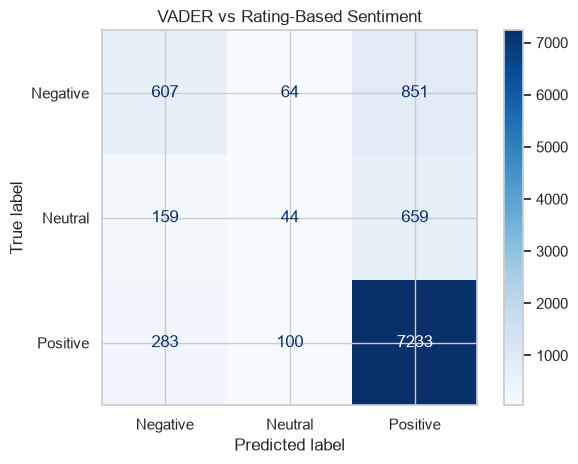

In [27]:
cm_vader = confusion_matrix(
    y_true,
    reviews["vader_sentiment"],
    labels=class_order
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_vader,
    display_labels=class_order
).plot(cmap="Blues", values_format="d")

plt.title("VADER vs Rating-Based Sentiment")
plt.tight_layout()
plt.show()

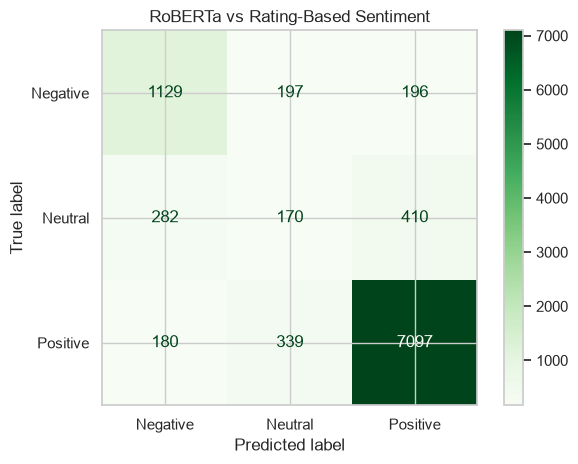

In [28]:
cm_roberta = confusion_matrix(
    y_true,
    reviews["roberta_sentiment"],
    labels=class_order
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_roberta,
    display_labels=class_order
).plot(cmap="Greens", values_format="d")

plt.title("RoBERTa vs Rating-Based Sentiment")
plt.tight_layout()
plt.show()

In [29]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

reviews.to_csv(
    output_dir / "sentiment_analysis_results.csv",
    index=False
)

comparison_metrics = []

for model_name, column in [
    ("VADER", "vader_sentiment"),
    ("RoBERTa", "roberta_sentiment")
]:
    comparison_metrics.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, reviews[column]),
        "Macro_F1": precision_recall_fscore_support(
            y_true,
            reviews[column],
            labels=class_order,
            average="macro",
            zero_division=0
        )[2]
    })

pd.DataFrame(comparison_metrics).to_csv(
    output_dir / "model_comparison_metrics.csv",
    index=False
)

print("Results saved to the outputs/ folder.")


Results saved to the outputs/ folder.


In [30]:
print("MODEL COMPARISON")
display(pd.DataFrame(comparison_metrics))

print("\nVADER vs RoBERTa agreement:")
print(
    f"{(reviews['vader_sentiment'] == reviews['roberta_sentiment']).mean():.2%}"
)

print("\nRATING-BASED SENTIMENT DISTRIBUTION")
display(reviews["rating_sentiment"].value_counts())

print("\nMODEL SENTIMENT DISTRIBUTIONS")
display(pd.crosstab(
    reviews["vader_sentiment"],
    reviews["roberta_sentiment"],
    rownames=["VADER"],
    colnames=["RoBERTa"]
))


MODEL COMPARISON


,Model,Accuracy,Macro_F1
0,VADER,0.7884,0.479572
1,RoBERTa,0.8396,0.622915



VADER vs RoBERTa agreement:
82.24%

RATING-BASED SENTIMENT DISTRIBUTION


rating_sentiment
Positive    7616
Negative    1522
Neutral      862
Name: count, dtype: int64


MODEL SENTIMENT DISTRIBUTIONS


RoBERTa,Negative,Neutral,Positive
VADER,,,
Negative,736,116,197
Neutral,76,57,75
Positive,779,533,7431


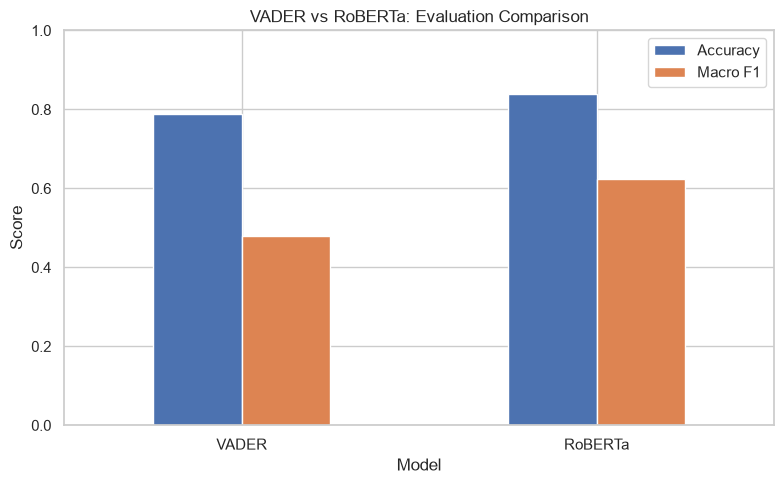

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics_df = pd.DataFrame(comparison_metrics).set_index("Model")

metrics_df[["Accuracy", "Macro_F1"]].plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1)
)

plt.title("VADER vs RoBERTa: Evaluation Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(["Accuracy", "Macro F1"])
plt.tight_layout()
plt.show()

In [32]:
reviews.head(10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,...,vader_neg,vader_neu,vader_pos,vader_compound,vader_sentiment,roberta_neg,roberta_neu,roberta_pos,roberta_sentiment,rating_sentiment
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...,...,0.000,0.695,0.305,0.9441,Positive,0.009624,0.049980,0.940395,Positive,Positive
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...,...,0.138,0.862,0.000,-0.5664,Negative,0.508986,0.452414,0.038600,Negative,Negative
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...,...,0.091,0.754,0.155,0.8265,Positive,0.003229,0.098068,0.898704,Positive,Positive
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...,...,0.000,1.000,0.000,0.0000,Neutral,0.002295,0.090219,0.907486,Positive,Negative
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...,...,0.000,0.552,0.448,0.9468,Positive,0.001635,0.010302,0.988063,Positive,Positive
5,6,B006K2ZZ7K,ADT0SRK1MGOEU,Twoapennything,0,0,4,1342051200,Nice Taffy,I got a wild hair for taffy and ordered this f...,...,0.029,0.809,0.163,0.8830,Positive,0.006130,0.021796,0.972075,Positive,Positive
6,7,B006K2ZZ7K,A1SP2KVKFXXRU1,David C. Sullivan,0,0,5,1340150400,Great! Just as good as the expensive brands!,This saltwater taffy had great flavors and was...,...,0.034,0.693,0.273,0.9346,Positive,0.001305,0.007774,0.990921,Positive,Positive
7,8,B006K2ZZ7K,A3JRGQVEQN31IQ,Pamela G. Williams,0,0,5,1336003200,"Wonderful, tasty taffy",This taffy is so good. It is very soft and ch...,...,0.000,0.520,0.480,0.9487,Positive,0.002029,0.005685,0.992285,Positive,Positive
8,9,B000E7L2R4,A1MZYO9TZK0BBI,R. James,1,1,5,1322006400,Yay Barley,Right now I'm mostly just sprouting this so my...,...,0.000,0.851,0.149,0.6369,Positive,0.003874,0.094156,0.901970,Positive,Positive
9,10,B00171APVA,A21BT40VZCCYT4,Carol A. Reed,0,0,5,1351209600,Healthy Dog Food,This is a very healthy dog food. Good for thei...,...,0.000,0.705,0.295,0.8313,Positive,0.003103,0.055912,0.940984,Positive,Positive
